In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv("penguins.csv")
df.head(),df.shape,df.dtypes
# This dataset has info about penguins species living on different islands.
# It has features like bill_length,bill_depth, flipper_length, body_mass,gender,calorie requirement ,year and  average sleep duration .

(  species     island  calorie requirement  average sleep duration  \
 0  Adelie  Torgersen                 6563                      11   
 1  Adelie  Torgersen                 4890                      14   
 2  Adelie  Torgersen                 7184                      11   
 3  Adelie  Torgersen                 4169                       8   
 4  Adelie  Torgersen                 4774                       8   
 
    bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g  gender  \
 0            39.1           18.7              181.0       3750.0    male   
 1            39.5           17.4              186.0       3800.0  female   
 2            40.3           18.0              195.0       3250.0  female   
 3             NaN            NaN                NaN        992.0     NaN   
 4            36.7           19.3              193.0       3450.0  female   
 
      year  
 0  2007.0  
 1  2007.0  
 2  2007.0  
 3  2007.0  
 4  2007.0  ,
 (344, 10),
 species               

In [3]:
print("statistics:",df.describe()),print("Missing counts: ",df.isnull().sum())
# island ,bill_length_mm ,bill_depth_mm,flipper_length_mm ,body_mass_g,gender,year  have missing values 

statistics:        calorie requirement  average sleep duration  bill_length_mm  \
count           344.000000              344.000000      337.000000   
mean           5270.002907               10.447674       45.494214   
std            1067.959116                2.265895       10.815787   
min            3504.000000                7.000000       32.100000   
25%            4403.000000                9.000000       39.500000   
50%            5106.500000               10.000000       45.100000   
75%            6212.750000               12.000000       49.000000   
max            7197.000000               14.000000      124.300000   

       bill_depth_mm  flipper_length_mm  body_mass_g         year  
count     333.000000         336.000000   339.000000   342.000000  
mean       18.018318         197.764881  4175.463127  2008.035088  
std         9.241384          27.764491   858.713267     0.816938  
min        13.100000          10.000000   882.000000  2007.000000  
25%        15.700

(None, None)

In [4]:
col_cat = ['species','island','gender','year']
col_num = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
df1 = df.copy()
for col in col_cat:
    df1[col] = df1[col].fillna(df1[col].mode()[0])
for col in col_num:
    df1[col] = df1[col].fillna(df1[col].mean())
print(df1.isnull().sum())


species                   0
island                    0
calorie requirement       0
average sleep duration    0
bill_length_mm            0
bill_depth_mm             0
flipper_length_mm         0
body_mass_g               0
gender                    0
year                      0
dtype: int64


In [5]:
strings=['species','island','gender']
for i in strings:
    df1[i]=df1[i].str.strip().str.lower().str.capitalize()

In [6]:
col_num = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
zscore=np.abs((df1[col_num]-df1[col_num].mean())/df1[col_num].std())
outliers=(zscore>3)
for c in col_num:
    median =df1[c].median()
    df1.loc[outliers[c],c]=float(median)

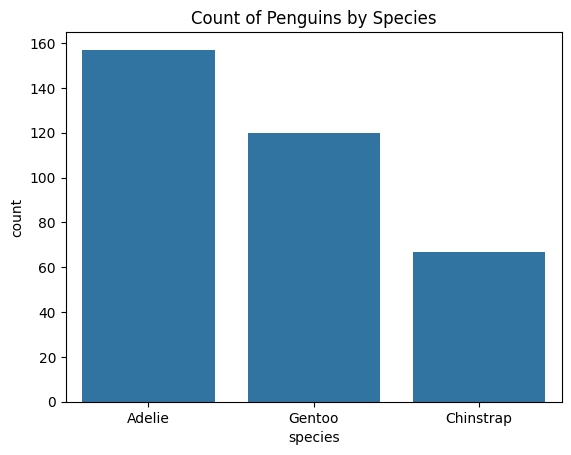

In [7]:
sns.countplot(x="species", data=df1)
plt.title("Count of Penguins by Species")
plt.show()
#here we count the species of penguins and we find that adelie has the highest count.

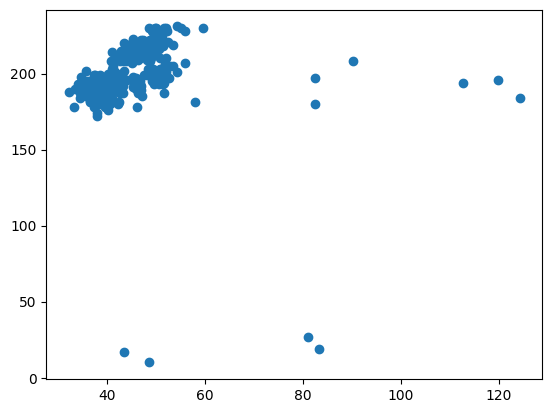

In [8]:
x=df['bill_length_mm']
y=df['flipper_length_mm']
plt.scatter(x,y)
plt.show()
# here we use scatterplot between bill and flipper length to understand their relation 

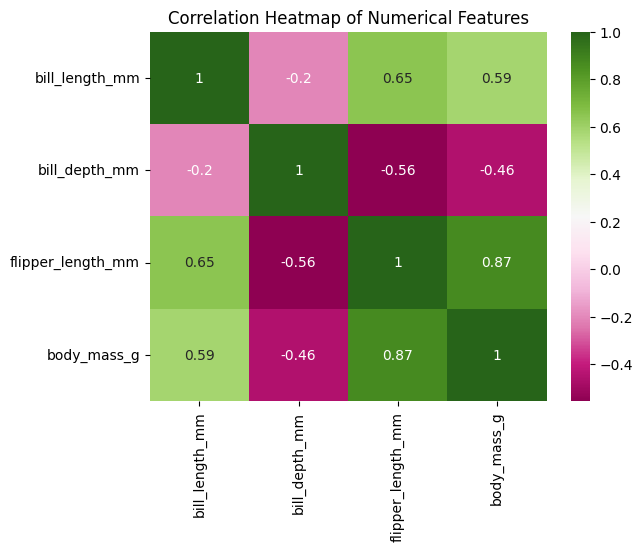

In [9]:
sns.heatmap(df1[col_num].corr(), annot=True, cmap="PiYG")
plt.title("Correlation Heatmap of Numerical Features")
plt.show()
#Here we are used to plot the relation betweeen different numerical features and we found out that bikk length and flipper length have positive correlation

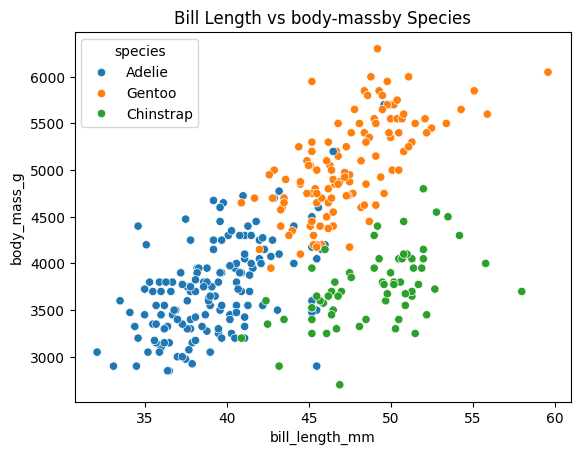

In [10]:
sns.scatterplot(x="bill_length_mm", y="body_mass_g", hue="species", data=df1)
plt.title("Bill Length vs body-massby Species")
plt.show()
#Here we use scatterplot among body and bill by using colours for different species

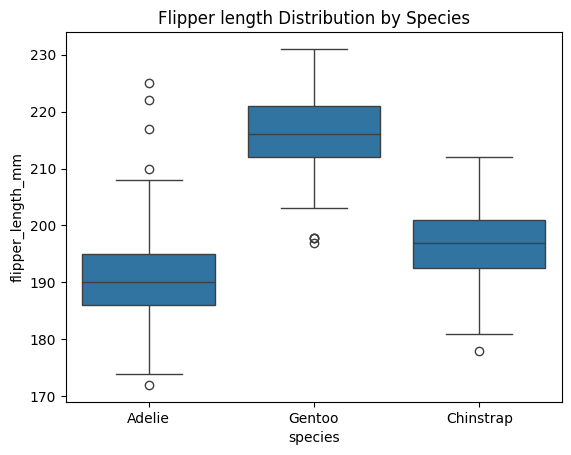

In [11]:
sns.boxplot(x="species", y="flipper_length_mm", data=df1)
plt.title("Flipper length Distribution by Species")
plt.show()
#Here we compare the flipper length distribution by species using box plot

In [12]:
df2=df1.copy()
df2['gender'] = df2['gender'].str.strip().str.lower()
df2['target_gender'] = df2['gender'].map({'male':1, 'female':0})
df3 = pd.get_dummies(df2[['species','island','year'] + col_num])
df3['target_gender'] = df2['target_gender']
correlation=df3.corr()
targetcorr = correlation['target_gender'].sort_values(ascending=False)
print(targetcorr)

target_gender        1.000000
body_mass_g          0.408337
bill_depth_mm        0.352013
bill_length_mm       0.332054
flipper_length_mm    0.247869
species_Gentoo       0.018471
island_Torgersen     0.016675
island_Biscoe        0.016458
species_Adelie      -0.000748
year                -0.017165
species_Chinstrap   -0.021289
island_Dream        -0.029814
Name: target_gender, dtype: float64


In [13]:
threshold=0.05
lowcorrelation=targetcorr[abs(targetcorr) < threshold]
print(lowcorrelation)
df4 = df3.drop(columns=lowcorrelation.index)

species_Gentoo       0.018471
island_Torgersen     0.016675
island_Biscoe        0.016458
species_Adelie      -0.000748
year                -0.017165
species_Chinstrap   -0.021289
island_Dream        -0.029814
Name: target_gender, dtype: float64


In [14]:
new=df1.copy()
new['target_island'] = new['island'].map({'Torgersen': 1, 'Biscoe': 0, 'Dream': 0})
df_island=pd.get_dummies(new[['species','gender','year'] + col_num])
df_island['target_island'] = new['target_island']
correlation = df_island.corr()
targetcorr = correlation['target_island'].sort_values(ascending=False)
threshold = 0.05
lowcorrelation = targetcorr[abs(targetcorr) < threshold]
df_final = df_island.drop(columns=lowcorrelation.index)


In [15]:
df_result = pd.get_dummies(df1, columns=['species', 'island', 'gender', 'year'])
c=['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
df_result[c] = (df_result[c] - df_result[c].min()) / (df_result[c].max() - df_result[c].min())

In [16]:
import pandas as pd
import numpy as np
class OutputPipeline:
    def __init__(self):
        self.settings = {}
    def fit_transform(self, df, n, c):
        num_cols = n
        cat_cols = c
        clean_df = df.copy()

        for col in cat_cols:
            m = clean_df[col].mode()[0]
            clean_df[col] = clean_df[col].fillna(m)
        for col in num_cols:
            mean_1 = clean_df[col].mean()
            clean_df[col] = clean_df[col].fillna(mean_1)

        for col in cat_cols:
            clean_df[col] = clean_df[col].astype(str).str.strip().str.lower()
        zscores = np.abs((clean_df[num_cols] - clean_df[num_cols].mean()) / clean_df[num_cols].std())
        for c in num_cols:
            clean_df[c] = clean_df[c].astype(float)
            median = clean_df[c].median()
            outliers = zscores > 3
            clean_df.loc[outliers[c], c] = median
        binary_cols, onehot_cols = [], []
        for col in list(cat_cols):
            if col not in clean_df.columns:
                continue
            unique_vals = clean_df[col].nunique()

            if unique_vals == 2:
                mapping = {val: i for i, val in enumerate(clean_df[col].unique())}
                clean_df[col] = clean_df[col].map(mapping)
                binary_cols.append(f"{col} (binary: {mapping})")

            elif unique_vals <= 50:
                dummies = pd.get_dummies(clean_df[col], prefix=col, drop_first=True)
                clean_df = pd.concat([clean_df.drop(columns=[col]), dummies], axis=1)
                onehot_cols.append(col)

        for c in num_cols:
            mean = clean_df[c].mean()
            std = clean_df[c].std()
            clean_df[c] = (clean_df[c] - mean) / (std if std > 0 else 1)

        self.settings = {
            "missing values": "Mode (categorical), Mean (numeric)",
            "outlier_strategy": "Z-score > 3 → median",
            "binary_encoded": binary_cols,
            "onehot_encoded": onehot_cols,
            "scaled_columns": num_cols,
            "scaling": "standardization (z-score)"
        }

        return clean_df
    def summary(self):
        return self.settings

In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   species                 333 non-null    object 
 1   island                  334 non-null    object 
 2   calorie requirement     344 non-null    int64  
 3   average sleep duration  344 non-null    int64  
 4   bill_length_mm          337 non-null    float64
 5   bill_depth_mm           333 non-null    float64
 6   flipper_length_mm       336 non-null    float64
 7   body_mass_g             339 non-null    float64
 8   gender                  327 non-null    object 
 9   year                    342 non-null    float64
dtypes: float64(5), int64(2), object(3)
memory usage: 27.0+ KB


In [18]:
pipe=OutputPipeline()
nums=['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g','year']
cats=['species','island','gender']

df_old=pipe.fit_transform(df,nums,cats)
print("Using reusable structure:",df_old.describe())

Using reusable structure:        calorie requirement  average sleep duration  bill_length_mm  \
count           344.000000              344.000000    3.440000e+02   
mean           5270.002907               10.447674    8.262125e-16   
std            1067.959116                2.265895    1.000000e+00   
min            3504.000000                7.000000   -2.235308e+00   
25%            4403.000000                9.000000   -8.359554e-01   
50%            5106.500000               10.000000    2.088943e-01   
75%            6212.750000               12.000000    8.106158e-01   
max            7197.000000               14.000000    2.895651e+00   

       bill_depth_mm  flipper_length_mm   body_mass_g      gender  \
count   3.440000e+02       3.440000e+02  3.440000e+02  344.000000   
mean    2.891744e-16      -1.569804e-15  6.196594e-16    0.470930   
std     1.000000e+00       1.000000e+00  1.000000e+00    0.499881   
min    -2.122983e+00      -2.075685e+00 -1.887629e+00    0.000000  

In [19]:
print("normal:",df_result.describe())

normal:        calorie requirement  average sleep duration  bill_length_mm  \
count           344.000000              344.000000      344.000000   
mean           5270.002907               10.447674        0.435651   
std            1067.959116                2.265895        0.194895   
min            3504.000000                7.000000        0.000000   
25%            4403.000000                9.000000        0.272727   
50%            5106.500000               10.000000        0.476364   
75%            6212.750000               12.000000        0.593636   
max            7197.000000               14.000000        1.000000   

       bill_depth_mm  flipper_length_mm  body_mass_g  
count     344.000000         344.000000   344.000000  
mean        0.488200           0.488871     0.417415  
std         0.229959           0.235523     0.221132  
min         0.000000           0.000000     0.000000  
25%         0.309524           0.305085     0.236111  
50%         0.523810           

In [20]:
df_old.to_csv("penguins_preprocessed.csv")


In [21]:
dataset1=pd.read_csv("diamond.csv")
print(dataset1.shape)
print(dataset1.head())
print(dataset1.dtypes)
print("This dataset gives information about the carat, cut, color , average salary,no of diamonds , depth, table proce and additional features like x,y,z")
dataset1['target']=dataset1['cut'].apply(lambda x: 1 if x in ['Ideal','Premium'] else 0)
print("Counts:",dataset1['target'].value_counts())
for col in ['carat', 'depth', 'table', 'price','x','y','z','number of diamonds mined (millions)','average us salary' ]:
    dataset1[col] = pd.to_numeric(dataset1[col], errors='coerce')
pipe=OutputPipeline()
nums=['carat', 'depth', 'table', 'price','x','y','z', 'number of diamonds mined (millions)','average us salary' ]
cats=['color', 'clarity']    
dataset1_preprocessed=pipe.fit_transform(dataset1,nums,cats)
print(pipe.summary())
dataset1_preprocessed.head()

dataset1_preprocessed.to_csv("diamond_preprocessed.csv")


(53940, 13)
  Unnamed: 0 carat      cut color clarity  average us salary  \
0          1  0.23    Ideal     E     SI2              31282   
1          2  0.21  Premium     E     SI1              40049   
2          3  0.23     Good     E     VS1              33517   
3          4  0.29  Premium     I     VS2              38495   
4          5  0.31     Good     J     SI2              34178   

   number of diamonds mined (millions) depth table price     x     y     z  
0                                 5.01  61.5    55   326  3.95  3.98  2.43  
1                                 1.69  59.8    61   326  3.89  3.84  2.31  
2                                 3.85  56.9    65   327  4.05  4.07  2.31  
3                                 3.49  62.4    58   334   4.2  4.23  2.63  
4                                 4.70  63.3    58   335  4.34  4.35  2.75  
Unnamed: 0                              object
carat                                   object
cut                                     object


In [22]:
print("After preprocessing Columns are:", dataset1_preprocessed.columns.tolist()[:20], "...") 
print("Rows:", dataset1_preprocessed.head())

After preprocessing Columns are: ['Unnamed: 0', 'carat', 'cut', 'average us salary', 'number of diamonds mined (millions)', 'depth', 'table', 'price', 'x', 'y', 'z', 'target', 'color_e', 'color_f', 'color_false', 'color_g', 'color_h', 'color_i', 'color_j', 'color_maybe'] ...
Rows:   Unnamed: 0     carat      cut  average us salary  \
0          1 -1.275917    Ideal          -1.501759   
1          2 -1.322111  Premium           0.096049   
2          3 -1.275917     Good          -1.094425   
3          4 -1.137334  Premium          -0.187172   
4          5 -1.091140     Good          -0.973956   

   number of diamonds mined (millions)     depth     table     price  \
0                             1.589257 -0.197608 -1.182552 -0.980871   
1                            -0.914543 -1.569897  1.807305 -0.980871   
2                             0.714436  0.044561 -0.185933 -0.980570   
3                             0.442939  0.528899  0.312376 -0.978465   
4                             1.3

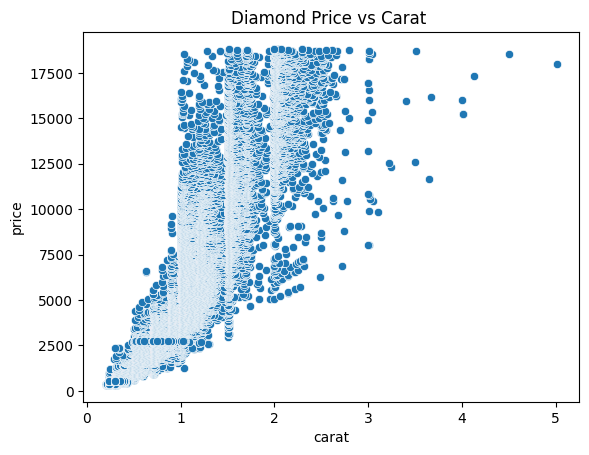

In [23]:
sns.scatterplot(data=dataset1, x="carat", y="price")
plt.title("Diamond Price vs Carat ")
plt.show()
#Here we are used to visualize the prices vs cart distribution using scatter plot

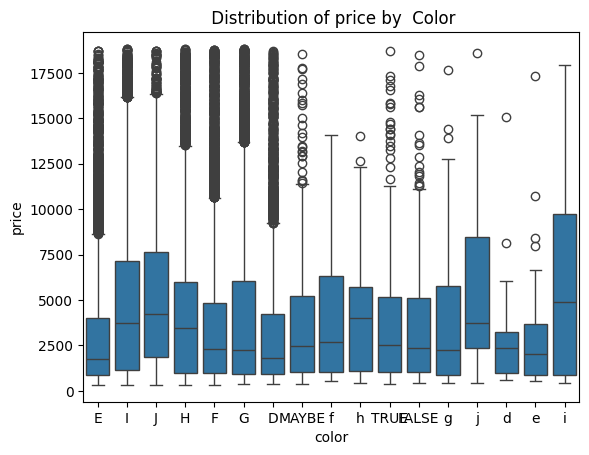

In [24]:
sns.boxplot(data=dataset1, x="color", y="price")
plt.title(" Distribution of price by  Color")
plt.show()
#Here the price distribution by color is plotted using boxplot

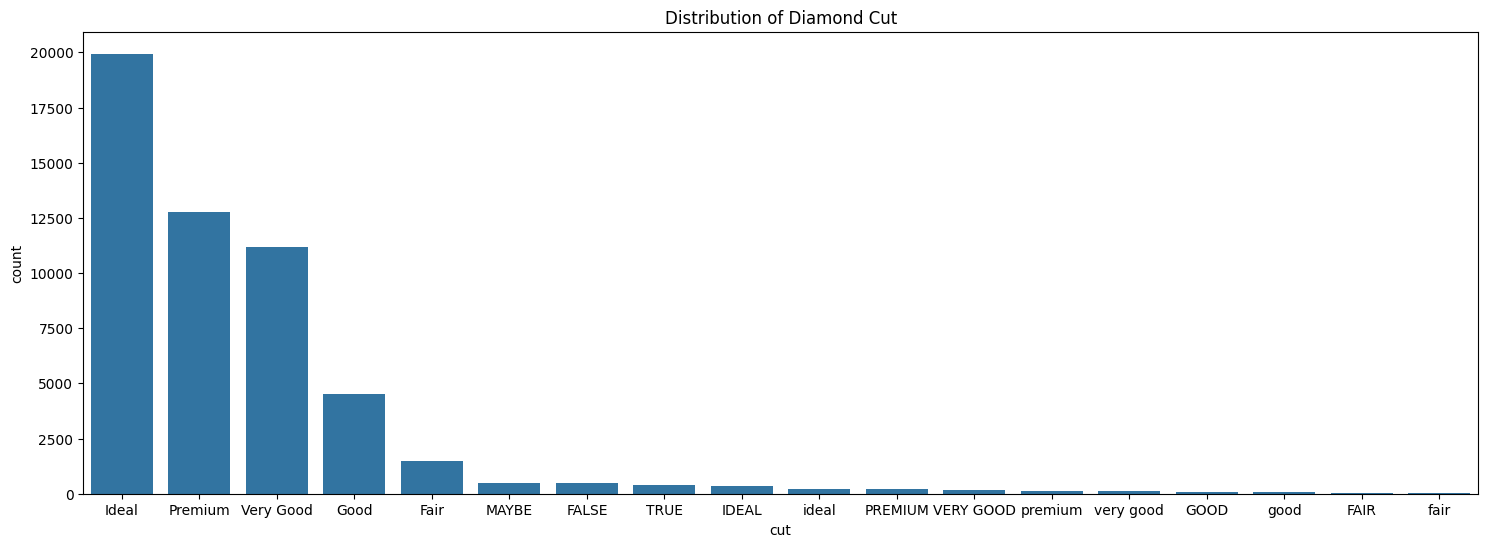

In [25]:
plt.figure(figsize=(18,6))
sns.countplot(data=dataset1, x="cut", order=dataset1['cut'].value_counts().index)
plt.title("Distribution of Diamond Cut")
plt.show()
#Here we count the cut using the count plot like ideal, premium, very good, good, fair .. 

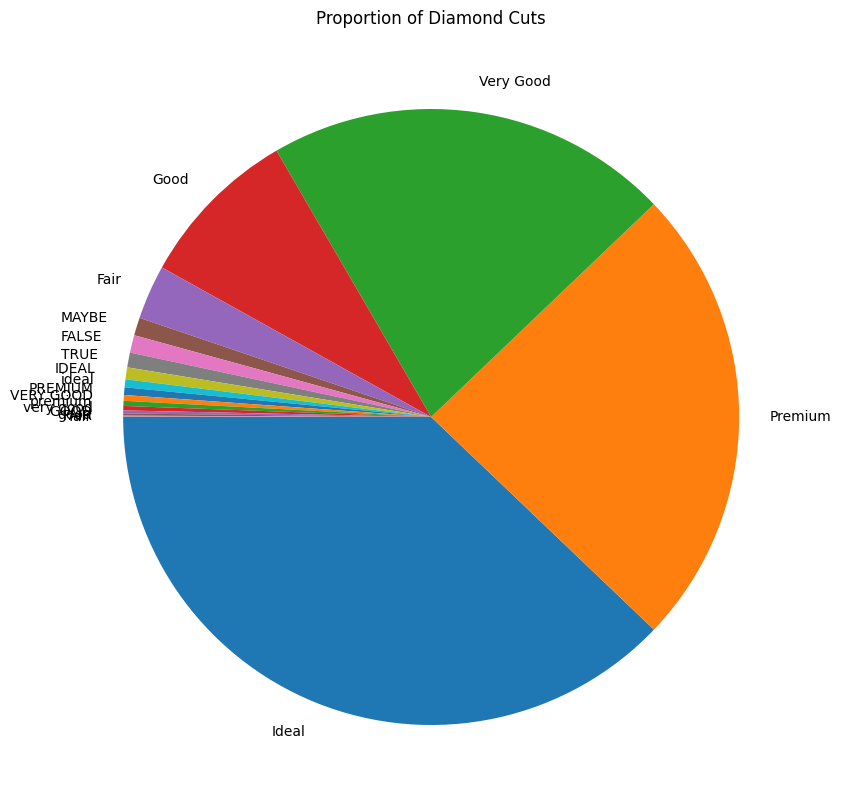

In [26]:
cutcounts = dataset1['cut'].value_counts()
plt.figure(figsize=(10,10))
plt.pie(cutcounts, labels=cutcounts.index,startangle=180)
plt.title("Proportion of Diamond Cuts")
plt.show()
#Here we used to plot the cut of the pie graphs ,telling us the portion of the cuts in the dataset 

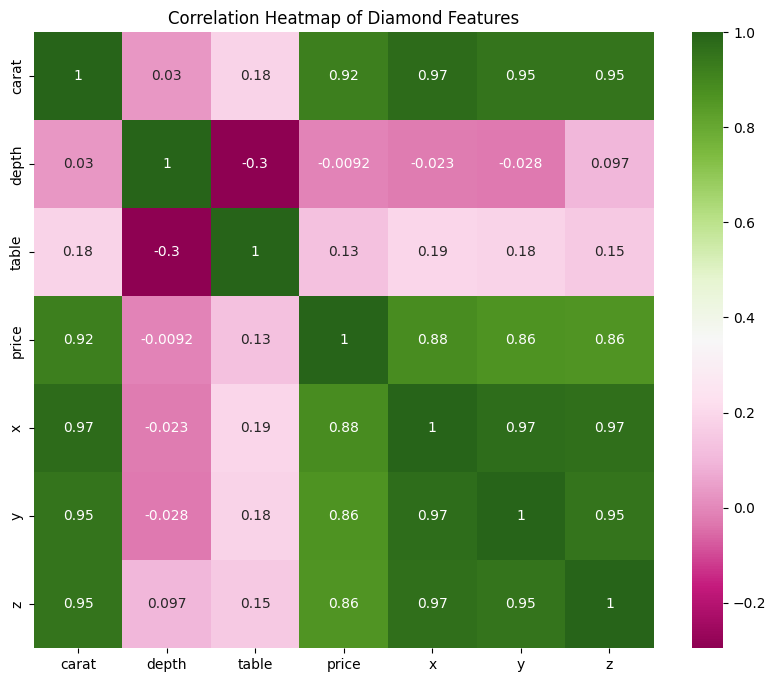

In [27]:
plt.figure(figsize=(10,8))
numeric_cols = ['carat','depth','table','price','x','y','z']
sns.heatmap(dataset1[numeric_cols].corr(), annot=True, cmap="PiYG")
plt.title("Correlation Heatmap of Diamond Features")
plt.show()

In [28]:
dataset2=pd.read_csv("breeding_bird_atlas.csv")
print(dataset2.shape)
print(dataset2.head())
print(dataset2.dtypes)
dataset2["target"]=dataset2['Breeding Status'].apply(lambda x: 1 if x == "Confirmed" else 0)
print("Counts:",dataset2['target'].value_counts())
nums = ['Fed. Region', 'Month', 'Day', 'Year', 'Temperature', 'Average UB Student GPA']
cats = ['Block ID', 'Map Link', 'County', 'Common Name', 'Scientific Name','NYS Protection Status', 'Family Name', 'Family Description', 'Breeding Behavior']
pipe = OutputPipeline()
dataset2_preprocessed = pipe.fit_transform(dataset2, nums, cats)
print(pipe.summary())

dataset2_preprocessed.to_csv("breeding_bird_preprocessed.csv")

(361582, 16)
   Fed. Region Block ID                                           Map Link  \
0          NaN    5773C                                                 50   
1          8.0    5569B  http://www.dec.ny.gov/data/dfwmr/bba/pdf/5569b...   
2          8.0    5773C  http://www.dec.ny.gov/data/dfwmr/bba/pdf/5773c...   
3          8.0    5872A  http://www.dec.ny.gov/data/dfwmr/bba/pdf/5872a...   
4          8.0    5570D  http://www.dec.ny.gov/data/dfwmr/bba/pdf/5570d...   

   County          Common Name        Scientific Name NYS Protection Status  \
0     NaN                  NaN                     12                    10   
1  ALBANY     Alder Flycatcher      Empidonax alnorum             Protected   
2  ALBANY  American Black Duck          Anas rubripes          Game Species   
3  ALBANY  American Black Duck          Anas rubripes          Game Species   
4  ALBANY        American Crow  Corvus brachyrhynchos          Game Species   

  Family Name     Family Description  \
0  

In [29]:
print("After preprocessing Columns are:", dataset2_preprocessed.columns.tolist()[:20], "...")  # first 20 cols
print("Rows:", dataset2_preprocessed.head())

After preprocessing Columns are: ['Fed. Region', 'Block ID', 'Map Link', 'County', 'Common Name', 'Scientific Name', 'NYS Protection Status', 'Family Name', 'Family Description', 'Breeding Behavior', 'Month', 'Day', 'Year', 'Temperature', 'Average UB Student GPA', 'Breeding Status', 'target'] ...
Rows:    Fed. Region Block ID                                           Map Link  \
0     0.150212    5773c                                                 50   
1     0.945670    5569b  http://www.dec.ny.gov/data/dfwmr/bba/pdf/5569b...   
2     0.945670    5773c  http://www.dec.ny.gov/data/dfwmr/bba/pdf/5773c...   
3     0.945670    5872a  http://www.dec.ny.gov/data/dfwmr/bba/pdf/5872a...   
4     0.945670    5570d  http://www.dec.ny.gov/data/dfwmr/bba/pdf/5570d...   

        County          Common Name        Scientific Name  \
0  st lawrence         song sparrow                     12   
1       albany     alder flycatcher      empidonax alnorum   
2       albany  american black duck      

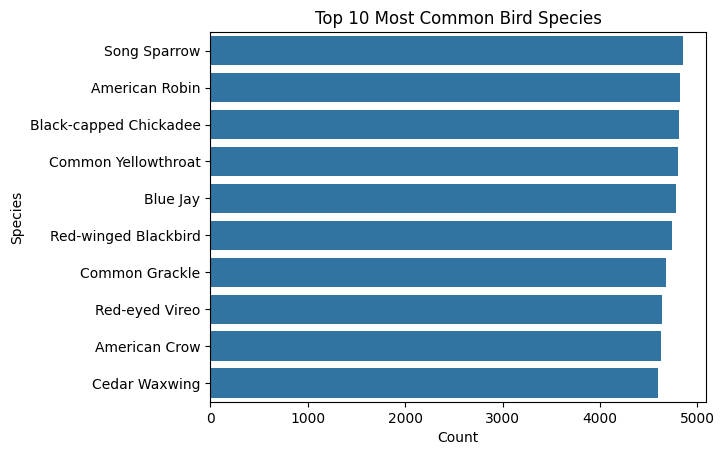

In [30]:
top_species = dataset2["Common Name"].value_counts().head(10)
sns.barplot(x=top_species.values, y=top_species.index)
plt.title("Top 10 Most Common Bird Species")
plt.xlabel("Count")
plt.ylabel("Species")
plt.show()
#Here this visualization represents the top 10 common bird species in the dataset 

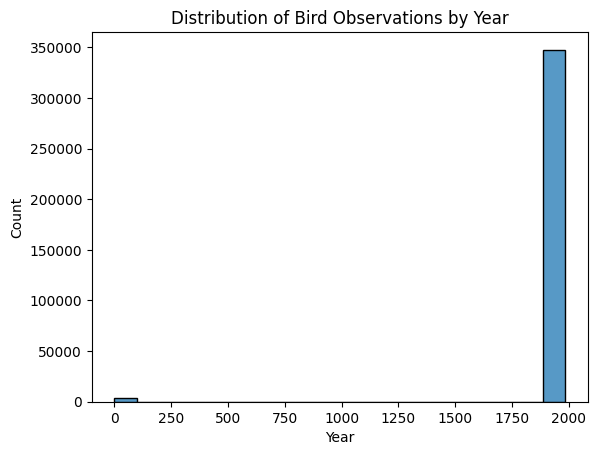

In [31]:
sns.histplot(dataset2["Year"].dropna(), bins=20, kde=False)
plt.title("Distribution of Bird Observations by Year")
plt.show()
#here we observe the distribution of birds over year

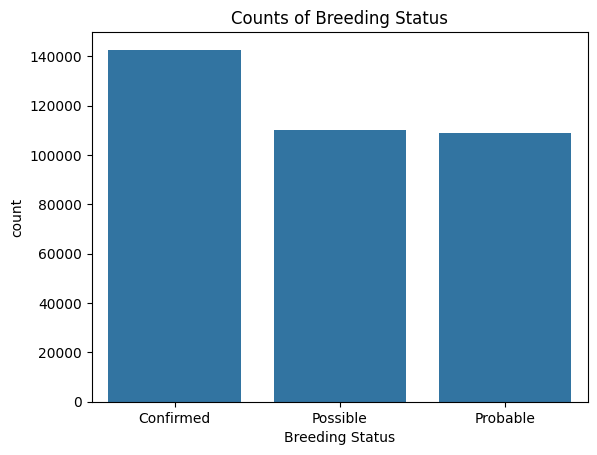

In [32]:
sns.countplot(data=dataset2, x="Breeding Status", order=dataset2["Breeding Status"].value_counts().index)
plt.title("Counts of Breeding Status")
plt.show()
#Here we are checking breeding status by calculating the count 

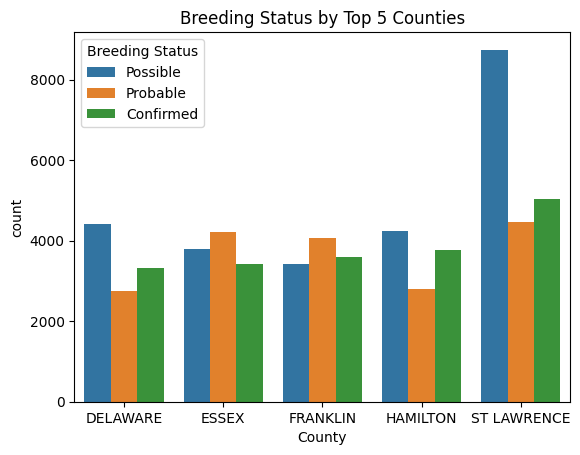

In [33]:
top_counties = dataset2["County"].value_counts().head(5).index
sns.countplot(data=dataset2[dataset2["County"].isin(top_counties)], x="County", hue="Breeding Status")
plt.title("Breeding Status by Top 5 Counties")
plt.show()
#Here it is used to classify the breeding status by countries and founf out possible breeding is in st lawrence

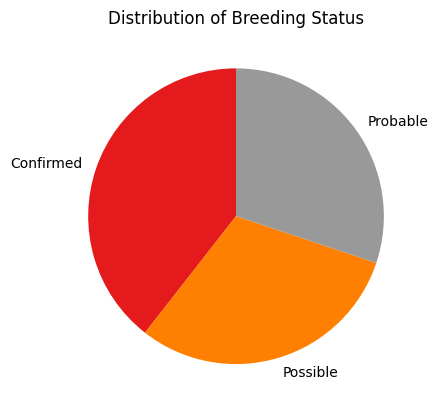

In [34]:
dataset2['Breeding Status'].value_counts().plot.pie(startangle=90, cmap="Set1")
plt.title("Distribution of Breeding Status")
plt.ylabel("")
plt.show()
#By plotting the breeding status we are seeing that confirmed  is more proportion

# References:
https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html
https://numpy.org/
https://matplotlib.org/
https://seaborn.pydata.org/

| Team Member | Assignment part | Contribution |
|----------|----------|----------|
| Odra Bira | Part 1  | 50% |
| Pranay Lachuluri | Part 2 | 50% |
| Odra Bira | Part 2  | 50% |
| Pranay Lachuluri | Part 1 | 50% |

